# Поиск кандидатов в аномалии в Yambda-50M

Этот ноутбук продолжает разведочный анализ (`01_eda.ipynb`). Там было выяснено, как выглядит обычное поведение пользователей: «всё или ничего» в дослушивании, суточный и недельный ритмы, различия органики и рекомендаций. Здесь нужно найти конкретных пользователей, чье поведение от этой нормы сильно отличается, и разобрать каждого вручную.

**Как устроен поиск.** Двумя способами:
1. **Проверка гипотез.** Формулируем, как мог бы вести себя бот (например, слушать ровно до порога засчитывания), и проверяем, есть ли такие пользователи.
2. **Поиск по набору признаков.** Для каждого пользователя считаем несколько признаков «нечеловеческого» поведения и ищем тех, у кого сразу несколько признаков сильно отклоняются от нормы (скрипт `src/bot_hunt.py`).

**Важно.** Разметки «бот / не бот» в данных нет, поэтому найденные пользователи — это **кандидаты**, а не доказанные боты. Для каждого мы проверяем невинные объяснения и делаем вывод о наиболее вероятной причине. Итог — каталог найденных аномалий в конце ноутбука.

Загружаем данные и сразу добавляем колонки, которые понадобятся дальше. Все преобразования объяснены в `01_eda.ipynb`.

In [140]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt

listens = (
    pl.read_parquet("../data/listens.parquet")
    .with_columns(pl.col("timestamp").cast(pl.Int64)) # знаковый тип, чтобы безопасно вычитать время
    .with_columns(
        (pl.col("timestamp") // 86400).alias("day"), # условный день от начала отсчета
        ((pl.col("timestamp") % 86400) // 3600).alias("hour"), # условный час суток
        (pl.col("track_length_seconds") * pl.col("played_ratio_pct") / 100).alias("played_sec"), # прослушано, с
    )
)
likes = pl.read_parquet("../data/likes.parquet").with_columns(pl.col("timestamp").cast(pl.Int64))

listeners = listens.select("uid").unique()
likes_no_listen = likes.join(listeners, on="uid", how="anti") # лайки от тех, кто ничего не слушал

users_skip = listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    (pl.col("played_ratio_pct") == 0).mean().alias("zero_share"),
)
active = users_skip.filter(pl.col("n_listens") >= 100)

## 1. Пользователи с очень высокой долей быстрых пропусков

В `01_eda.ipynb` на boxplot доли быстрых пропусков несколько пользователей заметно оторвались от остальных (доля 0,6–0,9). Нужно рассмотреть этих пользователей.

In [141]:
print(active.filter(pl.col("zero_share") > 0.6).sort("zero_share", descending=True))

shape: (7, 3)
┌────────┬───────────┬────────────┐
│ uid    ┆ n_listens ┆ zero_share │
│ ---    ┆ ---       ┆ ---        │
│ u32    ┆ u32       ┆ f64        │
╞════════╪═══════════╪════════════╡
│ 84000  ┆ 1157      ┆ 0.901469   │
│ 441700 ┆ 940       ┆ 0.874468   │
│ 929300 ┆ 1636      ┆ 0.800122   │
│ 176900 ┆ 242       ┆ 0.752066   │
│ 572900 ┆ 490       ┆ 0.64898    │
│ 126900 ┆ 762       ┆ 0.648294   │
│ 989300 ┆ 6067      ┆ 0.61101    │
└────────┴───────────┴────────────┘


**Результат:** у 7 активных пользователей доля быстрых пропусков превышает 60%, то есть больше половины треков они выключают в первые секунды. У самого крайнего (uid 84000) это 90% из 1 157 прослушиваний.

Большинство из них слушают немного: от 242 до 1 636 прослушиваний, тогда как медиана по всем пользователям — около 3 000 (25% пользователей имеют меньше 937 прослушиваний). Выделяется пользователь 989300: у него 6 067 прослушиваний, больше, чем у половины всех пользователей, и 61% из них — быстрые пропуски, то есть более 3 700 мгновенно выключенных треков. Это самый интересный кандидат: высокая доля пропусков при большом объёме активности не объясняется случайностью.

Сама по себе высокая доля пропусков не доказывает аномалию: пользователь может просто активно пролистывать музыку в поисках нужного трека. Чтобы понять, что стоит за таким поведением, нужно посмотреть на историю этих пользователей подробнее: какую долю составляет органика, как прослушивания распределены во времени, повторяются ли одни и те же треки.

Разберём двух самых показательных: 84000 (самая высокая доля пропусков) и 989300 (высокая доля пропусков при большой активности).

### Пользователь 84000 — сбой записи прогресса

In [142]:
u = listens.filter(pl.col("uid") == 84000)

# 1. Общая картина
print(u.select(
    pl.len().alias("прослушиваний"),
    pl.col("item_id").n_unique().alias("разных треков"),
    (pl.col("played_ratio_pct") == 0).mean().round(3).alias("доля мгнов. пропусков"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
    pl.col("day").n_unique().alias("активных дней"),
))

# 2. Не один ли трек он «пропускает» снова и снова
print(u.group_by("item_id").agg(
    pl.len().alias("раз"),
    (pl.col("played_ratio_pct") == 0).mean().round(2).alias("доля пропусков"),
).sort("раз", descending=True).head(5))

# 3. Паузы между событиями: сразу пачками или как человек листает
gaps = u.with_columns(pl.col("timestamp").diff().alias("gap"))["gap"]
print(gaps.describe())

shape: (1, 5)
┌───────────────┬───────────────┬───────────────────────┬───────────────┬───────────────┐
│ прослушиваний ┆ разных треков ┆ доля мгнов. пропусков ┆ доля органики ┆ активных дней │
│ ---           ┆ ---           ┆ ---                   ┆ ---           ┆ ---           │
│ u32           ┆ u32           ┆ f64                   ┆ f64           ┆ u32           │
╞═══════════════╪═══════════════╪═══════════════════════╪═══════════════╪═══════════════╡
│ 1157          ┆ 759           ┆ 0.901                 ┆ 0.01          ┆ 43            │
└───────────────┴───────────────┴───────────────────────┴───────────────┴───────────────┘
shape: (5, 3)
┌─────────┬─────┬────────────────┐
│ item_id ┆ раз ┆ доля пропусков │
│ ---     ┆ --- ┆ ---            │
│ u32     ┆ u32 ┆ f64            │
╞═════════╪═════╪════════════════╡
│ 2654961 ┆ 4   ┆ 1.0            │
│ 1464852 ┆ 3   ┆ 1.0            │
│ 7660460 ┆ 3   ┆ 1.0            │
│ 1816422 ┆ 3   ┆ 1.0            │
│ 8677248 ┆ 3   ┆ 1.0      

**Результат:** у пользователя 84000 90% прослушиваний записаны как мгновенные пропуски, но это не повтор одного трека: 759 разных треков на 1 157 событий, и ни один трек не встречается больше 4 раз. Почти все приходит из рекомендаций (органики 1%), активность распределена по 43 дням.

При этом паузы между событиями не похожи на быстрое пролистывание: медиана — 195 с, половина пауз — от 155 до 380 с, то есть примерно длина обычной песни. Если бы пользователь выключал трек в первую секунду, следующее событие начиналось бы через несколько секунд. Возникает подозрение, что треки на самом деле проигрывались целиком, а в данных записалось 0%. Нужно проверить совпадает ли пауза после «пропущенного» трека с его длиной.

In [143]:
u = listens.filter(pl.col("uid") == 84000).with_columns(
    pl.col("timestamp").diff().alias("gap"),
    pl.col("track_length_seconds").shift(1).alias("prev_len"),
    pl.col("played_ratio_pct").shift(1).alias("prev_pct"),
)

# для треков, «пропущенных» на 0%: пауза до следующего события / длина трека
u.filter(pl.col("prev_pct") == 0).with_columns(
    (pl.col("gap") / pl.col("prev_len")).alias("gap_to_len")
)["gap_to_len"].describe()

statistic,value
str,f64
"""count""",1042.0
"""null_count""",0.0
"""mean""",38.321062
"""std""",244.873259
"""min""",0.0
"""25%""",0.926829
"""50%""",1.2
"""75%""",2.515152
"""max""",3507.034483


**Результат:** для «пропущенных» треков (0% дослушивания) пауза до следующего события в медиане составляет 1,2 длины трека, а у половины таких треков — от 0,93 до 2,5 длины. То есть после почти каждого «мгновенного пропуска» проходит не меньше времени, чем длится сам трек: трек, скорее всего, проигрывался целиком, хотя в данных записано 0%. Значения больше 1 объясняются перерывами между треками и сессиями, поэтому среднее (38) завышено редкими длинными паузами и ориентироваться нужно на медиану.

**Вывод:** гипотеза подтвердилась. Треки, скорее всего, проигрывались целиком, а 0% — ошибка записи прогресса прослушивания. Пользователь слушает поток рекомендаций на устройстве или в приложении, которое не передаёт, какая часть трека прослушана (например, колонка, телевизор или автомобильная система). Это не аномальное поведение и не бот, а аномалия записи данных.

**Почему это важно:**
- рекомендательная модель воспримет такие события как отказ от почти всех рекомендаций, хотя пользователь, вероятно, их слушал;
- детектор, опирающийся на долю быстрых пропусков, даст здесь ложное срабатывание.

### Пользователь 989300 — повторяющиеся запуски одного трека

У этого пользователя 61% быстрых пропусков при 6 067 прослушиваниях. Посмотрим, не приходится ли большая часть пропусков на один и тот же трек.

In [144]:
u = listens.filter(pl.col("uid") == 989300)
top = u.group_by("item_id").len().sort("len", descending=True)["item_id"][0]
tt = u.filter(pl.col("item_id") == top)

print(tt.select(
    pl.len().alias("раз"),
    pl.col("track_length_seconds").first().alias("длина, с"),
    pl.col("played_ratio_pct").mean().round(0).alias("сред. % дослушивания"),
    (pl.col("played_ratio_pct") == 0).mean().round(3).alias("доля мгнов. пропусков"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
    pl.col("day").n_unique().alias("в скольких днях"),
))

t = listens.filter(pl.col("item_id") == top)
print("всего прослушиваний трека:", t.height, " слушателей:", t["uid"].n_unique())

# паузы между повторами этого трека
gaps = tt.with_columns(pl.col("timestamp").diff().alias("gap"))["gap"]
print("паузы между повторами, с:")
print(gaps.describe())

shape: (1, 6)
┌──────┬──────────┬──────────────────────┬───────────────────────┬───────────────┬─────────────────┐
│ раз  ┆ длина, с ┆ сред. % дослушивания ┆ доля мгнов. пропусков ┆ доля органики ┆ в скольких днях │
│ ---  ┆ ---      ┆ ---                  ┆ ---                   ┆ ---           ┆ ---             │
│ u32  ┆ u32      ┆ f64                  ┆ f64                   ┆ f64           ┆ u32             │
╞══════╪══════════╪══════════════════════╪═══════════════════════╪═══════════════╪═════════════════╡
│ 2908 ┆ 370      ┆ 0.0                  ┆ 0.999                 ┆ 1.0           ┆ 5               │
└──────┴──────────┴──────────────────────┴───────────────────────┴───────────────┴─────────────────┘
всего прослушиваний трека: 2908  слушателей: 1
паузы между повторами, с:
shape: (9, 2)
┌────────────┬───────────────┐
│ statistic  ┆ value         │
│ ---        ┆ ---           │
│ str        ┆ f64           │
╞════════════╪═══════════════╡
│ count      ┆ 2907.0        │
│ null

**Результат:** трек длиной 370 с записан 2 908 раз за 5 дней, при этом 99,9% событий — мгновенные пропуски (0% дослушивания), а большинство событий имеют одинаковое время (медиана паузы — 0 с). Других слушателей у трека в датасете нет.

**Вывод:** трек, по-видимому, не воспроизводился ни разу. Вероятное объяснение — трек недоступен, и плеер многократно пытается его запустить; альтернативное — автоматическая отправка событий запуска. Засчитанных прослушиваний это не создаёт, но даёт тысячи событий в данных для обучения. Это же объясняет высокую долю быстрых пропусков у пользователя.

**Итог раздела.** В обоих случаях высокая доля мгновенных пропусков оказалась связана не с тем, что пользователю не нравится музыка, а с особенностями записи данных: у 84000 прогресс прослушивания не записывается, у 989300 один и тот же недоступный трек тысячи раз запускается без воспроизведения. Значит, доля быстрых пропусков сама по себе — ненадёжный признак аномального поведения: её нужно дополнять проверкой пауз и повторов.

## 2. «Экономный» бот: проверка порогов засчитывания

В `01_eda.ipynb` было выявлено, что живые пользователи слушают по принципу «всё или ничего»: либо пропускают трек в первые секунды, либо дослушивают до конца. Бот для накрутки заинтересован, чтобы прослушивание засчиталось при минимальных затратах времени, поэтому он может слушать ровно до порога засчитывания и переключать трек. Нужно проверить оба варианта порога: 50% трека (правило датасета) и 30 секунд (типичный порог в музыкальных сервисах).

### Проверка порога засчитывания: 50%

Проверим идею «экономного» бота. Для каждого пользователя со 100+ прослушиваниями посчитаем долю прослушиваний, оборванных сразу после порога засчитывания — в диапазоне 50–55% трека. Если какой-то пользователь систематически останавливается сразу за порогом, у него эта доля будет аномально высокой.

In [145]:
users_threshold = listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    pl.col("played_ratio_pct").is_between(50, 55).mean().alias("share_50_55"),
).filter(pl.col("n_listens") >= 100)

print(users_threshold["share_50_55"].describe())
users_threshold.sort("share_50_55", descending=True).head()

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 8768.0   │
│ null_count ┆ 0.0      │
│ mean       ┆ 0.008752 │
│ std        ┆ 0.00602  │
│ min        ┆ 0.0      │
│ 25%        ┆ 0.004651 │
│ 50%        ┆ 0.007789 │
│ 75%        ┆ 0.011782 │
│ max        ┆ 0.08     │
└────────────┴──────────┘


uid,n_listens,share_50_55
u32,u32,f64
697800,100,0.08
338900,1276,0.076803
142900,120,0.058333
778000,231,0.051948
174300,11527,0.046586


**Результат:** у типичного пользователя (100+ прослушиваний) в диапазон 50–55% попадает меньше 1% прослушиваний: медиана — 0,78%, у 75% пользователей — не больше 1,2%. Отдельные пользователи заметно выделяются: максимум — 8%, примерно в 10 раз выше медианы. Однако у пользователя с максимальной долей всего 100 прослушиваний (8 событий), поэтому значение может быть случайным. Более устойчивые кандидаты — пользователи 338900 (7,7% из 1 276 прослушиваний, около 98 событий) и 174300 (4,7% из 11 527, около 537 событий).

Даже у крайних пользователей большая часть прослушиваний обычная, поэтому явных «экономных» ботов, систематически останавливающих трек сразу после порога в 50%, не найдено. Возможные причины: такого поведения в данных нет, либо реальный порог засчитывания задан в секундах, а не в процентах. Вторую версию проверяем отдельно.

### Проверка порога засчитывания: 30 секунд

Порог 50% — правило авторов датасета. В реальных музыкальных сервисах прослушивание часто засчитывается после фиксированного времени, например 30 секунд. Тогда «экономный» бот слушал бы каждый трек примерно 30–35 секунд независимо от его длины.

Для проверки посчитаем реально прослушанное время в секундах: `played_sec = track_length_seconds × played_ratio_pct / 100`, — и для каждого пользователя долю прослушиваний длительностью 30–35 с.

In [146]:
listens = listens.with_columns(
    (pl.col("track_length_seconds") * pl.col("played_ratio_pct") / 100).alias("played_sec")
)

users_30s = listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    pl.col("played_sec").is_between(30, 35).mean().alias("share_30_35"),
).filter(pl.col("n_listens") >= 100)

print(users_30s["share_30_35"].describe())
users_30s.sort("share_30_35", descending=True).head(10)

shape: (9, 2)
┌────────────┬──────────┐
│ statistic  ┆ value    │
│ ---        ┆ ---      │
│ str        ┆ f64      │
╞════════════╪══════════╡
│ count      ┆ 8768.0   │
│ null_count ┆ 0.0      │
│ mean       ┆ 0.009971 │
│ std        ┆ 0.008102 │
│ min        ┆ 0.0      │
│ 25%        ┆ 0.00526  │
│ 50%        ┆ 0.008559 │
│ 75%        ┆ 0.012926 │
│ max        ┆ 0.323028 │
└────────────┴──────────┘


uid,n_listens,share_30_35
u32,u32,f64
506900,938,0.323028
129600,4077,0.09247
927200,126,0.087302
270800,634,0.078864
91200,106,0.075472
511300,323,0.074303
664900,1395,0.073835
456700,128,0.0703125
488900,167,0.065868


**Результат:** один пользователь резко выделяется: у 506900 в диапазон 30–35 с попадает 32% прослушиваний (около 300 из 938), у следующего по этому показателю — только 9%. Это кандидат, которого стоит разобрать подробно: как распределено его время прослушивания, откуда он берёт треки и когда слушает.

### Разбор пользователя 506900

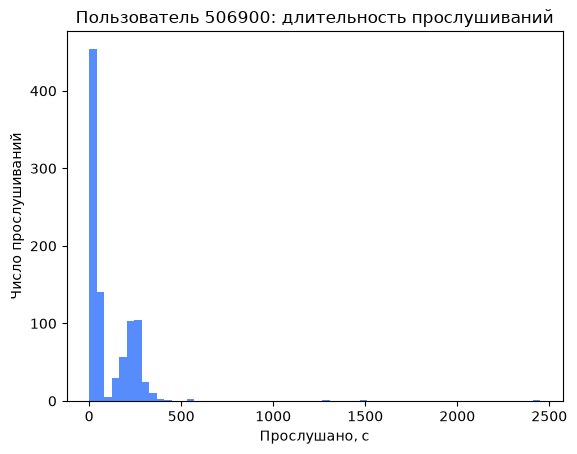

доля органики,разных треков,всего прослушиваний
f64,u32,u32
0.952026,343,938


In [147]:
u = listens.filter(pl.col("uid") == 506900)

# 1 Как распределено реально прослушанное время
plt.hist(u["played_sec"], bins=60)
plt.xlabel("Прослушано, с")
plt.ylabel("Число прослушиваний")
plt.title("Пользователь 506900: длительность прослушиваний")
plt.show()

# 2 Органика или рекомендации, сколько разных треков
u.select(
    pl.col("is_organic").mean().alias("доля органики"),
    pl.col("item_id").n_unique().alias("разных треков"),
    pl.len().alias("всего прослушиваний"),
)

Видим два горба: много коротких прослушиваний (примерно до 100 с) и отдельно — полные прослушивания обычных песен (150–300 с). Почти все прослушивания органические (95% при примерно 52% в среднем по всем пользователям), каждый трек он слушает в среднем почти 3 раза. Дальше смотрим, когда он слушает.

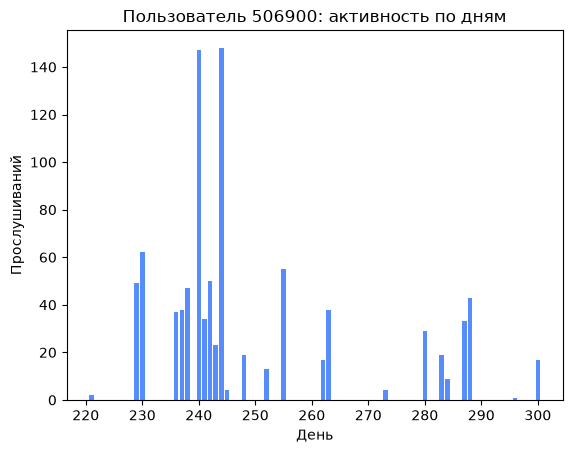

In [148]:
# 3 Когда он слушает: по дням
u_days = u.group_by("day").len().sort("day")
plt.bar(u_days["day"], u_days["len"])
plt.xlabel("День")
plt.ylabel("Прослушиваний")
plt.title("Пользователь 506900: активность по дням")
plt.show()

Аккаунт появляется только примерно на 221-й день из 300, активность рваная, с двумя всплесками (дни 240 и 244). При ширине столбцов около 50 с на первой гистограмме не видно, есть ли узкий пик именно около 30 секунд, поэтому посмотрим короткие прослушивания крупным планом.

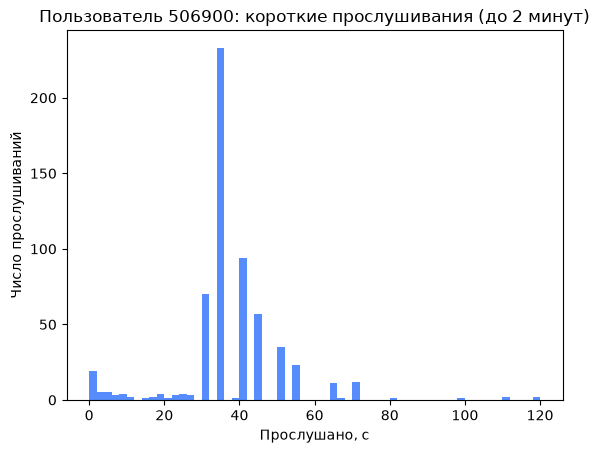

In [149]:
plt.hist(u.filter(pl.col("played_sec") <= 120)["played_sec"], bins=60)
plt.xlabel("Прослушано, с")
plt.ylabel("Число прослушиваний")
plt.title("Пользователь 506900: короткие прослушивания (до 2 минут)")
plt.show()

До 30 секунд прослушиваний почти нет, с 30 секунд — резкий подъём и пик около 35 с, дальше спад до 55–70 с. Получается «стена» на 30 секундах. Чтобы понять, необычно ли это, сравним с тем же графиком по всем пользователям.

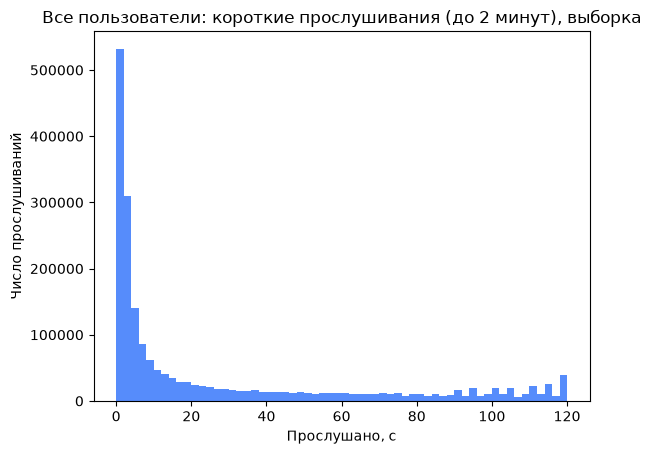

In [150]:
short_all = listens.filter(pl.col("played_sec") <= 120).sample(2_000_000, seed=42)

plt.hist(short_all["played_sec"], bins=60)
plt.xlabel("Прослушано, с")
plt.ylabel("Число прослушиваний")
plt.title("Все пользователи: короткие прослушивания (до 2 минут), выборка")
plt.show()

У всех пользователей картина обратная: больше всего прослушиваний обрывается в первые секунды, дальше плавный спад, никакого скачка около 30 с. Поведение 506900 явно выделяется на фоне остальных.

### Кандидат: пользователь 506900

**Как найден.** Была проверена гипотеза, что «экономный» бот для накрутки слушает трек ровно столько, сколько нужно для засчитывания. Порог в 50% трека ничего не дал, поэтому проверялся порог в секундах (30–35 с — обычный порог засчитывания в музыкальных сервисах). У пользователя 506900 в этот диапазон попадает 32% прослушиваний (около 300 из 938), у следующего по этому показателю — только 9%.

**Что видно при разборе:**
- **длительность прослушиваний:** до 30 секунд почти ничего нет, с 30 секунд — резкий подъём, пик около 35 с, затем спад примерно до 55–70 с; отдельно — около трети прослушиваний полных песен;
- **сравнение с фоном:** у всех пользователей картина обратная — больше всего пропусков в первые секунды, дальше плавный спад, без какого-либо скачка около 30 с;
- **источник:** 95% прослушиваний органические (по всем пользователям — около 52%);
- **треки:** 343 разных трека на 938 прослушиваний, в среднем почти по 3 раза каждый;
- **активность:** аккаунт появляется только примерно на 221-й день из 300, активность неравномерная, с двумя всплесками (дни 240 и 244, примерно по 147 прослушиваний).

**Предварительная интерпретация (на этом этапе).** Пользователь почти никогда не выключает трек раньше 30 секунд и чаще всего выключает его вскоре после этого порога. Это совпадает с ожидаемым поведением бота, который «добирает» засчитанные прослушивания с небольшим случайным разбросом. Альтернативные объяснения — прослушивание превью без подписки (но тогда пик был бы ровно на 30 с, без хвоста до 55–70 с) или привычка «пробовать» каждый трек по полминуты. По одним этим данным различить версии нельзя, но поведение явно выделяется на фоне всех остальных пользователей.

**Дальше:** проверить, какие треки он слушает по 30–55 секунд (одни и те же или разные), что происходило в дни всплесков, и есть ли другие пользователи с похожей «стеной» на 30 секундах.

Проверяем пункты из «Дальше»: сначала — какие треки кандидат слушает по 30–55 секунд.

In [ ]:
u.filter(pl.col("played_sec").is_between(30, 55)) \
 .group_by("item_id").len().sort("len", descending=True).head(10)

**Результат:** короткие прослушивания сосредоточены на ограниченном наборе треков: 10 самых частых прослушаны в этом режиме по 11–17 раз каждый. На этом этапе многократное прослушивание одного трека ровно по полминуты лучше согласуется с версией накрутки, чем с версией «пробует новую музыку». Посмотрим, есть ли другие пользователи с такой же «стеной».

In [ ]:
# похожие пользователи: много прослушиваний 30–55 с и мало ранних пропусков 1–29 с
wall = listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    pl.col("played_sec").is_between(30, 55).mean().alias("share_30_55"),
    pl.col("played_sec").is_between(1, 29).mean().alias("share_1_29"),
).filter(pl.col("n_listens") >= 100)

wall.sort("share_30_55", descending=True).head(10)

**Результат:** у 506900 54,7% прослушиваний длятся 30–55 с и всего 4,8% — от 1 до 29 с. Ближайший похожий пользователь, 431300, имеет 46,7% и 13,1%, но у него всего 122 прослушивания. У остальных доля ранних пропусков намного выше, то есть «стены» нет. Кандидат фактически единственный.

Если трек накручивают, обычно это делает не один аккаунт. Проверим, кто ещё слушает топ-треки кандидата и как.

In [ ]:
top_items = (
    u.filter(pl.col("played_sec").is_between(30, 55))
    .group_by("item_id").len().sort("len", descending=True)
    .head(10)["item_id"]
)

listens.filter(pl.col("item_id").is_in(top_items.implode())).group_by("item_id").agg(
    pl.len().alias("всего прослушиваний"),
    pl.col("uid").n_unique().alias("разных слушателей"),
    pl.col("played_sec").is_between(30, 55).mean().round(2).alias("доля 30–55 с"),
).sort("всего прослушиваний", descending=True)

**Результат:** у этих треков очень мало слушателей (6–13 человек на весь датасет), и почти все их прослушивания, не только у 506900, длятся 30–55 с (72–100%). Это похоже на группу аккаунтов, одинаково слушающих одни и те же редкие треки.

Но сначала нужно исключить два невинных объяснения: это могут быть просто очень короткие треки, которые слушают до конца, или треки, доступные только в виде превью. Посмотрим на длину треков и процент дослушивания.

In [ ]:
listens.filter(pl.col("item_id").is_in(top_items.implode())).group_by("item_id").agg(
    pl.col("track_length_seconds").first().alias("длина трека, с"),
    pl.col("played_ratio_pct").mean().round(0).alias("сред. % дослушивания"),
    pl.col("played_sec").mean().round(0).alias("сред. прослушано, с"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
)

**Результат:** все 10 треков длятся всего 30–45 секунд, а дослушивают их в среднем на 78–100%. Значит, «30–55 секунд прослушано» здесь означает просто «трек дослушан до конца». Первое невинное объяснение подтвердилось. Проверим, кто эти другие слушатели.

In [ ]:
listeners_of_top = (
    listens.filter(pl.col("item_id").is_in(top_items.implode()))
    .group_by("uid").agg(
        pl.col("item_id").n_unique().alias("сколько из топ-10 слушал"),
        pl.len().alias("прослушиваний"),
    )
    .sort("сколько из топ-10 слушал", descending=True)
)
listeners_of_top

**Результат:** несколько пользователей прослушали все 10 треков примерно по одному разу. Вероятно, это один альбом или сборник коротких треков (все прослушивания органические), который слушают целиком.

**Вывод по кандидату:** гипотеза об «экономном» боте для пользователя 506900 не подтвердилась. «Стена» на 30 секундах объясняется тем, что он много слушает очень короткие треки, а не прерывает длинные после порога. **Кандидат исключен**

Отсюда важное следствие: время прослушивания в секундах нельзя использовать как признак в отрыве от длины трека, иначе короткие треки дают ложные срабатывания. Чтобы честно проверить гипотезу о пороге в 30 секунд, повторим поиск только по трекам длиной от 90 секунд.

In [ ]:
long_tracks = listens.filter(pl.col("track_length_seconds") >= 90)

wall_long = long_tracks.group_by("uid").agg(
    pl.len().alias("n_listens"),
    pl.col("played_sec").is_between(30, 55).mean().alias("share_30_55"),
    pl.col("played_sec").is_between(1, 29).mean().alias("share_1_29"),
).filter(pl.col("n_listens") >= 100)

wall_long.sort("share_30_55", descending=True).head(10)

**Проверка на длинных треках.** Чтобы исключить влияние коротких треков, повторили поиск только по трекам длиной от 90 секунд. Максимальная доля прослушиваний длительностью 30–55 с у пользователей (100+ прослушиваний) — около 25%, и у этих пользователей велика также доля прослушиваний короче 30 с (22–62%), то есть это обычное пролистывание, а не прерывание сразу после порога. Единственное исключение — пользователь 238200 (21,8% прослушиваний длительностью 30–55 с при 5,9% более коротких), но у него всего 101 прослушивание длинных треков, поэтому оценка ненадёжна.

**Вывод:** пользователей, систематически прерывающих прослушивание вскоре после 30 секунд, в данных не обнаружено. Если такие «экономные» боты в сервисе и были, в датасет они, по-видимому, не попали или были удалены при подготовке. Поэтому для проверки детекторов на этом типе аномалий понадобятся синтетические боты.

## 3. Оценки без прослушиваний

### Кандидаты: оценки без прослушиваний

**Гипотеза:** среди 762 пользователей без прослушиваний есть аккаунты, которые ставят очень много оценок за короткое время. Живой человек, не слушая музыку, не станет лайкать сотни треков за час; для накрутки лайков это типичное поведение.

**Проверка:** для каждого такого пользователя считаем число лайков, период активности и максимальное число лайков за один час.

In [ ]:
no_listen_likes = likes_no_listen.with_columns(
    (pl.col("timestamp") // 3600).alias("hour_abs") # номер часа от начала отсчета
)

per_hour_user = no_listen_likes.group_by(["uid", "hour_abs"]).len()

likes_stats = no_listen_likes.group_by("uid").agg(
    pl.len().alias("n_likes"),
    ((pl.col("timestamp").max() - pl.col("timestamp").min()) / 86400).round(1).alias("период, дней"),
).join(
    per_hour_user.group_by("uid").agg(pl.col("len").max().alias("макс. лайков за час")),
    on="uid",
)

likes_stats["n_likes"].describe()

In [ ]:
likes_stats.sort("макс. лайков за час", descending=True).head(10)

**Результат:** большинство пользователей без прослушиваний ставят умеренное число лайков: медиана — 86 за весь период, у 75% — не больше 194. Однако у некоторых лайки сосредоточены во времени: пользователь 844900 поставил 471 лайк за один час (из 822 за весь период), 193200 — 219 за час, 536500 — 198 за час (всего 2 230 лайков). При этом большинство этих пользователей активны почти весь период (около 300 дней), то есть это не одноразовые аккаунты.

Сотни лайков за час без единого прослушивания похожи на массовое проставление оценок. Есть и невинное объяснение: перенос медиатеки из другого сервиса или массовое добавление треков в «Мне нравится» из плейлиста, когда сотни лайков появляются разом. Кроме того, прослушивания этих пользователей могли просто не попасть в датасет. Для окончательного вывода нужно сравнить с тем, сколько лайков за час ставят обычные слушающие пользователи, и посмотреть, какие треки лайкаются.

**Кандидаты:** 844900, 193200, 536500 — массовые оценки без прослушиваний.

In [ ]:
lk = likes.join(listeners, on="uid").with_columns((pl.col("timestamp") // 3600).alias("hour_abs"))
normal = lk.group_by(["uid", "hour_abs"]).len().group_by("uid").agg(pl.col("len").max().alias("макс. лайков за час"))
normal["макс. лайков за час"].describe()

**Результат:** у обычных слушающих пользователей максимум лайков за один час в медиане равен 5, у 75% — не больше 11. Однако массовые всплески встречаются и у них: максимум — 7 092 лайка за час. Значит, сам по себе большой всплеск лайков не аномалия; важно, как он устроен. Посмотрим на вспышки трёх кандидатов подробнее.

### Пользователь 844900

In [ ]:
u = likes.filter(pl.col("uid") == 844900).with_columns((pl.col("timestamp") // 3600).alias("hour_abs"))
peak = u.group_by("hour_abs").len().sort("len", descending=True)["hour_abs"][0]
burst = u.filter(pl.col("hour_abs") == peak).sort("timestamp")

print("лайков во вспышке:", burst.height)
print("длилась, мин:", (burst["timestamp"].max() - burst["timestamp"].min()) / 60)
print("пауза между лайками, с:")
print(burst["timestamp"].diff().describe())

In [ ]:
items = burst["item_id"].unique()
others = likes.filter(pl.col("item_id").is_in(items.implode()))
print("разных треков во вспышке:", items.len())
print("сколько других пользователей лайкали эти треки:", others["uid"].n_unique() - 1)
print(others.group_by("item_id").agg(pl.col("uid").n_unique().alias("лайкнувших")).sort("лайкнувших").describe())

### Пользователь 193200

In [ ]:
u = likes.filter(pl.col("uid") == 193200).with_columns((pl.col("timestamp") // 3600).alias("hour_abs"))
peak = u.group_by("hour_abs").len().sort("len", descending=True)["hour_abs"][0]
burst = u.filter(pl.col("hour_abs") == peak).sort("timestamp")

print("лайков во вспышке:", burst.height)
print("длилась, мин:", (burst["timestamp"].max() - burst["timestamp"].min()) / 60)
print("пауза между лайками, с:")
print(burst["timestamp"].diff().describe())

In [ ]:
items = burst["item_id"].unique()
others = likes.filter(pl.col("item_id").is_in(items.implode()))
print("разных треков во вспышке:", items.len())
print("сколько других пользователей лайкали эти треки:", others["uid"].n_unique() - 1)
print(others.group_by("item_id").agg(pl.col("uid").n_unique().alias("лайкнувших")).sort("лайкнувших").describe())

### Пользователь 536500

In [ ]:
u = likes.filter(pl.col("uid") == 536500).with_columns((pl.col("timestamp") // 3600).alias("hour_abs"))
peak = u.group_by("hour_abs").len().sort("len", descending=True)["hour_abs"][0]
burst = u.filter(pl.col("hour_abs") == peak).sort("timestamp")

print("лайков во вспышке:", burst.height)
print("длилась, мин:", (burst["timestamp"].max() - burst["timestamp"].min()) / 60)
print("пауза между лайками, с:")
print(burst["timestamp"].diff().describe())

In [ ]:
items = burst["item_id"].unique()
others = likes.filter(pl.col("item_id").is_in(items.implode()))
print("разных треков во вспышке:", items.len())
print("сколько других пользователей лайкали эти треки:", others["uid"].n_unique() - 1)
print(others.group_by("item_id").agg(pl.col("uid").n_unique().alias("лайкнувших")).sort("лайкнувших").describe())

In [ ]:
from pathlib import Path
from huggingface_hub import hf_hub_download

# таблица снятых лайков: скачиваем один раз в data/, дальше читаем локально
unlikes_path = Path("../data/flat/50m/unlikes.parquet")
if not unlikes_path.exists():
    hf_hub_download(repo_id="yandex/yambda", repo_type="dataset",
                    filename="flat/50m/unlikes.parquet", local_dir="../data")
unlikes = pl.read_parquet(unlikes_path)
print(unlikes.filter(pl.col("uid") == 536500).height)

In [ ]:
ul = unlikes.filter(pl.col("uid") == 536500).with_columns(
    pl.col("timestamp").cast(pl.Int64),
    (pl.col("timestamp").cast(pl.Int64) // 3600).alias("hour_abs"),
)
lk = likes.filter(pl.col("uid") == 536500)

print("снятых лайков:", ul.height, " разных треков:", ul["item_id"].n_unique())
print("лайков:", lk.height, " разных треков:", lk["item_id"].n_unique())

# сколько треков и лайкал, и снимал
both = set(ul["item_id"].to_list()) & set(lk["item_id"].to_list())
print("треков, которые и лайкал, и снимал:", len(both))

# сколько раз в среднем снимал лайк с одного трека
print(ul.group_by("item_id").len()["len"].describe())

# максимум снятий за час и как распределены по дням
print("макс. снятий за час:", ul.group_by("hour_abs").len()["len"].max())
d = ul.with_columns((pl.col("timestamp") // 86400).alias("day")).group_by("day").len().sort("day")
plt.bar(d["day"], d["len"]); plt.title("536500: снятые лайки по дням"); plt.show()

**536500 — циклическая постановка и снятие лайков.** За весь период у пользователя нет ни одного прослушивания, зато 2 230 лайков всего на 368 треков (в среднем около 6 лайков на трек) и 5 647 снятых лайков на 960 треков (до 26 снятий с одного трека). 364 из 368 лайкнутых треков пользователь и лайкал, и снимал лайк, то есть одни и те же треки многократно переключаются между «нравится» и «не нравится». Активность идёт вспышками до 534 снятий лайка за час, на протяжении нескольких месяцев (дни 0–170 и 280–300) с перерывом около 110 дней.

**Вывод:** такое поведение невозможно для живого пользователя и не похоже на разовый импорт медиатеки. Вероятные объяснения — сбой синхронизации лайков между устройствами или сервисами либо автоматический скрипт. В обоих случаях данные содержат тысячи противоречивых сигналов по одним и тем же трекам, которые искажают обучение рекомендательной модели. Пользователь 536500 — один из самых явных кандидатов в аномалии среди найденных.

**Итог по оценкам без прослушиваний:** у всех трёх пользователей с массовыми лайками без прослушиваний лайкнутые треки разнообразные и популярные (в медиане 18–57 других лайкнувших на трек), поэтому признаков скоординированной накрутки лайков нет. При этом характер вспышек различается:
- **844900:** 471 лайк в один момент времени (в пределах 5 с) — вероятно, импорт медиатеки или синхронизация;
- **193200:** 219 лайков за 18 минут, примерно по одному каждые 5 секунд — похоже на быстрое ручное проставление лайков по списку или плейлисту;
- **536500:** 198 лайков за час, из них 34 — повторные лайки уже лайкнутых треков. Проверка по таблице снятых лайков показала, что это циклическое переключение лайков (см. выше), не похожее на поведение живого пользователя.

**Вывод:** у 844900 и 193200 массовые лайки без прослушиваний объясняются скорее особенностями использования (импорт медиатеки, быстрое проставление лайков), чем ботами. Пользователь 536500, напротив, — один из самых явных кандидатов: многократное переключение лайков по одним и тем же трекам похоже на сбой синхронизации или скрипт. Для рекомендательной модели такие всплески всё равно требуют осторожности: сотни лайков за минуты отражают одно действие пользователя, а не сотни отдельных реакций.

## 4. Активность без перерыва на сон

### Кандидаты: активность без ночного перерыва

**Гипотеза:** у обычного пользователя ночью активность падает (у всех вместе на условные часы 0–2 приходится всего около 3,7% прослушиваний). Если бы прослушивания шли равномерно круглые сутки, на эти 3 часа приходилось бы 12,5% (3 из 24). Пользователь, у которого ночная доля близка к 12,5% или выше, слушает без перерыва на сон — кандидат в боты.

**Проверка:** для активных пользователей (1 000+ прослушиваний) считаем долю прослушиваний в условные часы 0–2 и число часов суток, в которые пользователь вообще бывает активен.

In [ ]:
night = listens.group_by("uid").agg(
    pl.len().alias("n_listens"),
    pl.col("hour").is_between(0, 2).mean().alias("night_share"),
    pl.col("hour").n_unique().alias("активных часов"),
).filter(pl.col("n_listens") >= 1000)

night["night_share"].describe()

In [ ]:
per_hour = listens.group_by("hour").len().sort("hour")
colors = ["red" if h <= 2 else "tab:blue" for h in per_hour["hour"]]

plt.bar(per_hour["hour"], per_hour["len"], color=colors)
plt.xlabel("Условный час суток")
plt.ylabel("Число прослушиваний")
plt.title("Прослушивания по часам (красным — часы 0–2)")
plt.show()

In [ ]:
plt.hist(night["night_share"], bins=50)
plt.axvline(0.125, color="red", linestyle="--", label="равномерно круглые сутки (12,5%)")
plt.xlabel("Доля прослушиваний в условные часы 0–2")
plt.ylabel("Число пользователей")
plt.title("Ночная активность (пользователи с 1 000+ прослушиваний)")
plt.legend()
plt.show()

night.sort("night_share", descending=True).head(10)

**Результат:** у типичного активного пользователя на условные часы 0–2 приходится около 1% прослушиваний (медиана; у 75% пользователей — не больше 4%). У отдельных пользователей эта доля достигает 45–77%, но они активны лишь в 16–23 часа из 24, то есть у них тоже есть период без активности, просто сдвинутый во времени. Скорее всего, это пользователи из других часовых поясов или работающие ночью, а не боты, слушающие круглые сутки.

Значит, доля ночных прослушиваний зависит от часового пояса и как признак аномалии ненадёжна. Лучше использовать признак, не зависящий от часового пояса: долю прослушиваний в самом тихом для данного пользователя трёхчасовом окне. У человека в любом часовом поясе она мала, у бота, работающего круглые сутки, близка к 12,5%.

In [ ]:
# считаем прослушивания по часам для каждого активного пользователя
uh = (
    listens.join(night.select("uid"), on="uid")
    .group_by(["uid", "hour"]).len()
    .pivot(on="hour", index="uid", values="len")
    .fill_null(0)
)

uids = uh["uid"].to_numpy()
counts = uh.select([str(h) for h in range(24)]).to_numpy()   # матрица: пользователи × 24 часа
shares = counts / counts.sum(axis=1, keepdims=True)

# сумма по каждому окну из 3 часов подряд (с переходом через полночь)
windows = sum(np.roll(shares, -k, axis=1) for k in range(3))
quiet_share = windows.min(axis=1)    # доля в самом тихом окне пользователя

quiet = pl.DataFrame({"uid": uids, "quiet_3h_share": quiet_share}).join(night, on="uid")
quiet["quiet_3h_share"].describe()

In [ ]:
quiet.sort("quiet_3h_share", descending=True).head(15)

In [ ]:
for t in [0.03, 0.05, 0.08, 0.10]:
    n = quiet.filter(pl.col("quiet_3h_share") >= t).height
    print(f"quiet_3h_share >= {t}: {n} пользователей")

In [ ]:
print("пользователей с 24 активными часами:", quiet.filter(pl.col("активных часов") == 24).height, "из", quiet.height)

In [ ]:
suspects = quiet.filter(pl.col("quiet_3h_share") >= 0.08).sort("quiet_3h_share", descending=True)
suspect_ids = suspects["uid"].to_list()
print('подозреваемые пользователи:', *suspect_ids)

**Результат:** число активных часов не подходит как признак: у 2 362 из 6 817 активных пользователей (35%) за весь период было хотя бы одно прослушивание в каждом часе суток. Информативнее доля прослушиваний в самом тихом трёхчасовом окне пользователя: у большинства она равна нулю или близка к нему (медиана — 0,1%), а с ростом порога число пользователей быстро падает — 626 пользователей с долей от 3%, 253 — от 5%, 35 — от 8% и всего 4 — от 10%. При равномерной круглосуточной активности эта доля составила бы 12,5%.

**Вывод:** в качестве кандидатов «без времени сна» берём 35 пользователей с долей от 8%: даже в самые тихие для них часы они слушают почти столько же, сколько слушали бы при активности круглые сутки. Порог выбран по распределению, а не по месту в топ-10, и согласуется с результатами поиска по набору признаков.

Чтобы понять, что стоит за отсутствием «времени сна», соберём для этих 35 пользователей сводку по нескольким признакам: длина сессий, часы музыки в сутки, повторы одного трека, доля органики и пропусков. Признаки посчитаны скриптом `src/bot_hunt.py` и подробно описаны в разделе 6.

In [ ]:
features = pl.read_parquet("../data/user_features_hunt.parquet")

summary = suspects.select("uid", "quiet_3h_share", "n_listens").join(
    features.select("uid", "max_session_h", "max_hours_per_day", "days_over_16h",
                    "max_same_in_a_row", "top_item_share"),
    on="uid", how="left",
).join(
    listens.group_by("uid").agg(
        pl.col("is_organic").mean().round(2).alias("доля органики"),
        (pl.col("played_ratio_pct") == 0).mean().round(2).alias("доля мгнов. пропусков"),
    ),
    on="uid",
).sort("quiet_3h_share", descending=True)

pl.Config.set_tbl_rows(50)
summary

In [ ]:
summary = summary.with_columns(
    pl.when(pl.col("days_over_16h") >= 5).then(pl.lit("круглосуточное воспроизведение"))
    .when(pl.col("max_same_in_a_row") >= 70).then(pl.lit("зацикливание"))
    .otherwise(pl.lit("обычная высокая активность"))
    .alias("группа")
)
print(summary.group_by("группа").len())

**Предварительный результат** (ниже он уточняется более точными версиями признака)**:** 35 пользователей без «времени сна» неоднородны и делятся на три группы:
- **круглосуточное воспроизведение (9 пользователей)** — 5 и более дней по 16+ часов музыки, непрерывные сессии от суток и длиннее; часто преобладают рекомендации и почти нет пропусков. Самый явный случай — 246000: 45 таких дней, сессия 101 час, 0% органических прослушиваний и 0% пропусков;
- **зацикливание (5 пользователей)** — нет круглосуточных дней, но один трек звучит 70–160 раз подряд; эти пользователи разобраны в разделе 5;
- **вероятно, обычная высокая активность (21 пользователь)** — дней по 16+ часов нет или один, сессии в основном до 15 часов, повторов мало. Вероятно, это пользователи с нерегулярным режимом или аккаунты, которыми пользуются несколько человек, то есть ложные срабатывания одного признака.

**Предварительный вывод:** признак «нет времени сна» сам по себе не отличает аномальное потребление от просто очень активного: из 35 пользователей явно аномальны около 14. Для надёжного обнаружения его нужно сочетать с другими признаками — длиной сессий, числом дней с круглосуточной активностью и повторами.

### Пользователь 246000 — круглосуточное воспроизведение

In [ ]:
u = listens.filter(pl.col("uid") == 246000)

# часы музыки по дням
d = u.group_by("day").agg((pl.col("played_sec").sum() / 3600).alias("hours")).sort("day")
plt.figure(figsize=(12, 4))
plt.bar(d["day"], d["hours"]); plt.axhline(24, color="red")
plt.title("246000: часов музыки в день"); plt.show()

# общая картина
print(u.select(
    pl.len().alias("прослушиваний"),
    pl.col("item_id").n_unique().alias("разных треков"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
    (pl.col("played_ratio_pct") >= 100).mean().round(2).alias("доля дослушанных до конца"),
    pl.col("day").n_unique().alias("активных дней"),
))

**246000 — непрерывный поток рекомендаций без участия человека.** Аккаунт появляется около 148-го дня и с самого начала проигрывает музыку блоками по 1–3 недели, по 15–24 часа в сутки. Из 26 013 прослушиваний (4 181 разный трек) доля органических и доля недослушанных до конца после округления до сотых равны нулю, то есть почти всё пришло из рекомендаций и почти всё дослушано: за весь период у пользователя почти нет пропусков и треков, выбранных вручную, тогда как в среднем по датасету не засчитывается больше трети прослушиваний. Такое поведение не похоже на живого слушателя, вероятно, поток рекомендаций включается на длительное время и проигрывается без участия человека, например как фоновая музыка в заведении или на забытом устройстве. Для накрутки конкретных треков такой аккаунт бесполезен: треки разные, и каждый звучит лишь несколько раз. Это самый «чистый» пример круглосуточного воспроизведения в данных.

### Пользователь 196700 — круглосуточное воспроизведение после паузы

Ещё один пользователь из этой группы: сессия без пауз длиной около 347 часов, нет «времени сна». Посмотрим, сколько часов музыки он слушает в каждый день периода.

In [ ]:
# 196700: сколько часов в день он слушает
u = listens.filter(pl.col("uid") == 196700)
d = u.group_by("day").agg((pl.col("played_sec").sum() / 3600).alias("hours")).sort("day")
plt.bar(d["day"], d["hours"]); plt.axhline(24, color="red")
plt.title("196700: часов музыки в день"); plt.show()

Примерно первые 170 дней — обычный малоактивный пользователь: от 0 до 6 часов музыки в день, с пропусками. Затем почти три месяца без активности, а примерно с 265-го дня и до конца — 20–24 часа ежедневно. Сравним поведение до и после паузы: тот же ли это «вкус» и как он слушает.

In [ ]:
u = listens.filter(pl.col("uid") == 196700)
before = set(u.filter(pl.col("day") < 200)["item_id"].to_list())
after = set(u.filter(pl.col("day") >= 260)["item_id"].to_list())
print("треков до:", len(before), " после:", len(after), " общих:", len(before & after))

print(u.group_by(pl.col("day") >= 260).agg(
    pl.len().alias("прослушиваний"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
    (pl.col("played_ratio_pct") == 0).mean().round(3).alias("доля быстрых пропусков"),
))

**Результат:** до паузы пользователь сам выбирал музыку (88% органических прослушиваний) и заметно пропускал треки (15,6% быстрых пропусков). После паузы почти всё приходит из рекомендаций (94%), а пропусков почти нет (0,5%). Около 43% треков, прослушанных до паузы (699 из 1 617), встречаются и после, поэтому версия о полной смене владельца маловероятна: рекомендательный поток строится по истории аккаунта и подсовывает знакомое.

**Вывод:** на аккаунте включили рекомендательный поток и оставили его играть круглые сутки без участия человека (бот, фоновая музыка в заведении или забытое устройство). Такие события искажают обучение: модель учится на прослушиваниях, которых никто не слушал, причём на собственных рекомендациях.

### Пользователь 169500 — вероятно, обычный активный человек

In [ ]:
u = listens.filter(pl.col("uid") == 169500)

h = u.group_by("hour").len().sort("hour")
plt.bar(h["hour"], h["len"]); plt.title("169500: по часам"); plt.show()

d = u.group_by("day").agg((pl.col("played_sec").sum() / 3600).alias("hours")).sort("day")
plt.figure(figsize=(12, 4))
plt.bar(d["day"], d["hours"]); plt.title("169500: часов в день"); plt.show()

**169500 — вероятно, ложное срабатывание.** Прослушивания пользователя почти равномерно распределены по всем часам суток, поэтому у него нет «тихого» окна за период в целом. Однако по дням поведение обычное: от 0 до 13 часов музыки в день, без круглосуточных дней, с перерывами в активности. Скорее всего, у пользователя нерегулярный режим (сон в разное время в разные дни) или аккаунтом пользуются несколько человек.

**Ограничение признака:** доля в самом тихом окне, посчитанная по всему периоду, не различает «не спит вообще» и «спит в разное время». Надёжнее считать «время сна» для каждого дня отдельно — например, самый длинный перерыв в активности за сутки — и смотреть, есть ли он в большинстве дней.

In [ ]:
# самый длинный перерыв внутри каждого дня, для подозреваемых
gaps = (
    listens.filter(pl.col("uid").is_in(suspect_ids))
    .sort(["uid", "timestamp"])
    .with_columns(pl.col("timestamp").diff().over("uid").alias("gap"))
)

daily_gap = gaps.group_by(["uid", "day"]).agg(
    (pl.col("gap").max() / 3600).alias("max_gap_h")
)

sleep_check = daily_gap.group_by("uid").agg(
    pl.len().alias("активных дней"),
    (pl.col("max_gap_h") >= 5).mean().round(2).alias("доля дней с перерывом 5+ ч"),
    pl.col("max_gap_h").median().round(1).alias("медиана макс. перерыва, ч"),
).join(summary.select("uid", "группа"), on="uid").sort("доля дней с перерывом 5+ ч")

pl.Config.set_tbl_rows(50)
sleep_check

**Результат (первая версия).** Признак в целом разделяет группы: самые низкие доли дней с перерывом на сон у пользователей с круглосуточным воспроизведением (49% у 246000, 63–80% у 196700, 56100, 473400, 562200, 855200, 886700), а у пользователей с обычной высокой активностью и зацикливанием перерыв на сон есть в 84–98% дней.

**Ограничение:** перерыв считается от предыдущего прослушивания, даже если оно было в другой день, поэтому после пауз в активности в «самый длинный перерыв за день» попадают перерывы длиной в сутки и больше (отсюда медианы по 15–56 часов), и доли дней с перерывом завышены. Попробуем учитывать только перерывы внутри одного дня и только дни с активным прослушиванием.

In [ ]:
gaps2 = (
    listens.filter(pl.col("uid").is_in(suspect_ids))
    .sort(["uid", "timestamp"])
    .with_columns(
        pl.col("timestamp").diff().over("uid").alias("gap"),
        pl.col("day").shift(1).over("uid").alias("prev_day"),
    )
    .with_columns(  # перерыв считаем, только если предыдущее событие было в тот же день
        pl.when(pl.col("day") == pl.col("prev_day")).then(pl.col("gap")).alias("gap_in_day")
    )
)

daily2 = gaps2.group_by(["uid", "day"]).agg(
    (pl.col("gap_in_day").max() / 3600).alias("max_gap_h"),
    (pl.col("played_sec").sum() / 3600).alias("hours"),
).filter(pl.col("hours") >= 8)   # только дни, когда слушал 8+ часов

sleep_check2 = daily2.group_by("uid").agg(
    pl.len().alias("дней с 8+ ч"),
    (pl.col("max_gap_h") >= 5).mean().round(2).alias("доля таких дней с перерывом 5+ ч"),
).join(summary.select("uid", "группа"), on="uid").sort("доля таких дней с перерывом 5+ ч")
sleep_check2

**Результат (вторая версия).** Учитывали только перерывы внутри одного дня и только дни, когда пользователь слушал 8 и более часов музыки. Надёжные результаты получены для пользователей с большим числом таких дней: 196700 (35 дней, ни в одном нет перерыва 5+ часов), 246000 (65 дней, перерыв лишь в 2%), 855200 (62 дня, 5%), 56100 (42 дня, 12%) и 224200 (19 дней, 5%). Это наиболее уверенные случаи круглосуточного воспроизведения.

У многих других пользователей таких дней всего 1–10, и доли для них ненадёжны. Кроме того, у этой версии есть систематическая ошибка: граница условных суток (вероятно, полночь по UTC, то есть 3 часа ночи по Москве) разрезает ночной сон на две части, каждая из которых может оказаться короче 5 часов, и доля дней с перерывом у обычных пользователей занижается. Поэтому в третьей версии время не делится на сутки: считаем число длинных перерывов на один активный день.

In [ ]:
gaps3 = (
    listens.filter(pl.col("uid").is_in(suspect_ids))
    .sort(["uid", "timestamp"])
    .with_columns(pl.col("timestamp").diff().over("uid").alias("gap"))
)

sleep_check3 = gaps3.group_by("uid").agg(
    pl.col("day").n_unique().alias("активных дней"),
    (pl.col("gap") >= 5 * 3600).sum().alias("перерывов 5+ ч"),
).with_columns(
    (pl.col("перерывов 5+ ч") / pl.col("активных дней")).round(2).alias("перерывов на активный день")
).join(summary.select("uid", "группа"), on="uid").sort("перерывов на активный день")

sleep_check3

**Версия признака: длинные перерывы на активный день.** Чтобы не зависеть ни от часового пояса, ни от границы суток, для каждого пользователя посчитали число перерывов между прослушиваниями длиной 5 часов и больше и разделили на число активных дней. У человека, который спит каждый день, это значение около 1 и выше; у круглосуточного воспроизведения — заметно меньше 1.

**Результат:** признак чётко разделяет пользователей с границей около 1. Значения меньше 1 у всех пользователей с круглосуточным воспроизведением (от 0,49 у 246000 до 0,93 у 562200), а также у 224200 (0,84), который до этого был отнесён к обычной активности. Все пользователи с обычной высокой активностью и с зацикливанием имеют значения от 1,02 до 1,41: длинный перерыв на сон у них есть почти каждый день. Исключение — 449800 (1,09): несмотря на несколько очень длинных дней, он в целом спит регулярно и ближе к обычным пользователям. Пользователь 911200 (0,94, всего 31 активный день) — пограничный случай.

**Итог по 35 пользователям без «времени сна»:** 9 — круглосуточное воспроизведение (246000, 196700, 473400, 56100, 224200, 858000, 886700, 855200, 562200), 1 — пограничный (911200), остальные 25 — обычные очень активные пользователи, в том числе 5 с зацикливанием любимого трека.

**Вывод о признаках:** понадобилось три версии признака «нет времени сна». Доля прослушиваний в самом тихом окне за весь период путает «не спит» и «спит в разное время»; самый длинный перерыв внутри суток искажается границей суток, разрезающей ночной сон. Число длинных перерывов на активный день свободно от обоих недостатков и даёт наиболее чистое разделение.

In [ ]:
gaps_all = (
    listens.sort(["uid", "timestamp"])
    .with_columns(pl.col("timestamp").diff().over("uid").alias("gap"))
)

sleep_all = gaps_all.group_by("uid").agg(
    pl.col("day").n_unique().alias("активных дней"),
    (pl.col("gap") >= 5 * 3600).sum().alias("перерывов 5+ ч"),
).filter(pl.col("активных дней") >= 30).with_columns(
    (pl.col("перерывов 5+ ч") / pl.col("активных дней")).round(2).alias("перерывов на активный день")
).sort("перерывов на активный день")

print(sleep_all.filter(pl.col("перерывов на активный день") < 0.9))
print("новых, кого не было среди 35:",
      sleep_all.filter((pl.col("перерывов на активный день") < 0.9) & ~pl.col("uid").is_in(suspect_ids)).height)

In [ ]:
new_ids = sleep_all.filter(
    (pl.col("перерывов на активный день") < 0.9) & ~pl.col("uid").is_in(suspect_ids)
)["uid"].to_list()

new_summary = sleep_all.filter(pl.col("uid").is_in(new_ids)).join(
    features.select("uid", "quiet_3h_share", "max_session_h", "max_hours_per_day",
                    "days_over_16h", "max_same_in_a_row", "top_item_share"),
    on="uid", how="left",
).join(
    listens.group_by("uid").agg(
        pl.len().alias("прослушиваний"),
        pl.col("is_organic").mean().round(2).alias("доля органики"),
        (pl.col("played_ratio_pct") == 0).mean().round(2).alias("доля мгнов. пропусков"),
    ),
    on="uid",
).sort("перерывов на активный день")

pl.Config.set_tbl_cols(20)
new_summary

**Проверка по всем пользователям.** Чтобы проверить, не пропустил ли исходный отбор кого-то, признак «длинных перерывов на активный день» посчитали для всех пользователей с 30 и более активными днями. Значение меньше 0,9 получили ещё 16 пользователей, не вошедших в исходные 35.

**Результат:** найденные пользователи делятся на две группы.
- **Пропущенное круглосуточное воспроизведение (5 пользователей):** 107300, 264400, 516500, 79700, 706700 — непрерывные сессии от 17 до 43 часов, до 15 дней по 16+ часов музыки, почти исключительно рекомендации и ни одного пропуска. Самый явный случай — 107300 (15 таких дней); в исходный отбор он не попал, так как доля в самом тихом окне у него 7,4%, чуть ниже порога 8%. Такие пользователи активны круглосуточно лишь в отдельные периоды, поэтому признак, посчитанный по всему периоду, их пропускал.
- **Ложные срабатывания (около 10 пользователей):** сессии 2–6 часов, 2–4 часа музыки в день, круглосуточных дней нет. Низкое значение признака у них объясняется тем, что сессия, переходящая через границу условных суток, учитывается как два активных дня при одном перерыве перед ней.

Отдельно выделяется 980700: самая длинная сессия всего 5,6 минуты при 10,6 часа музыки в день, то есть прослушивания записаны пачками с одинаковым временем — это аномалия записи данных, а не круглосуточное воспроизведение.

**Вывод:** признак «перерывов на активный день» находит случаи, которые пропускает доля в тихом окне, но около значения 1 даёт ложные срабатывания у малоактивных пользователей. Надёжнее использовать его вместе с длиной сессий или числом часов музыки в день. С учётом этой проверки к круглосуточному воспроизведению относятся 14 пользователей.

## 5. Зацикливание: многократные повторы одного трека

В разделе 4 у пяти пользователей без «времени сна» нашлись длинные серии повторов одного трека, ещё у трёх круглосуточное воспроизведение сочеталось с повторами. Кроме того, по таблице признаков (`max_same_in_a_row`) сильнее всех выделяется 550800: 672 повтора подряд. Разберём, что стоит за такими повторами: режим повтора, увлечение треком или накрутка.

### Пользователь 550800 — один трек по кругу

89% всех прослушиваний — один трек, 672 раза подряд, сессия 24 часа. Что это за трек и как он его слушает?

In [ ]:
u = listens.filter(pl.col("uid") == 550800)
top = u.group_by("item_id").len().sort("len", descending=True)["item_id"][0]

# 1 Что за трек и как он его слушает
print(u.filter(pl.col("item_id") == top).select(
    pl.len().alias("раз"),
    pl.col("track_length_seconds").first().alias("длина, с"),
    pl.col("played_ratio_pct").mean().round(0).alias("сред. % дослушивания"),
    (pl.col("played_ratio_pct") == 0).mean().round(3).alias("доля мгнов. пропусков"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
))

# 2 Слушают ли его другие
t = listens.filter(pl.col("item_id") == top)
print("всего прослушиваний трека:", t.height, " слушателей:", t["uid"].n_unique())

# 3 В какие дни и сколько раз в день
d = u.filter(pl.col("item_id") == top).group_by("day").len().sort("day")
plt.bar(d["day"], d["len"]); plt.title("550800: прослушивания топ-трека по дням"); plt.show()

In [ ]:
# 4 По часам: все время суток или только ночью
h = u.group_by("hour").len().sort("hour")
plt.bar(h["hour"], h["len"]); plt.title("550800: по часам"); plt.show()

**Результат:** трек длиной 125 с, каждый раз дослушан до конца, все прослушивания органические. Трек популярный: 38 804 прослушивания от 4 652 пользователей. Пользователь прослушал его 681 раз за 2–3 дня (около 385 и 288 раз в сутки), причём равномерно по всем часам суток — около 28 раз в час, то есть трек играл непрерывно.

**Вывод:** зацикленное воспроизведение — скорее всего, режим повтора одного трека был оставлен включённым. Накрутка маловероятна: трек и так популярен. Но для рекомендательной модели такие данные создают сильный перекос в профиле пользователя.

### Пользователь 762100 — зацикливание

In [ ]:
u = listens.filter(pl.col("uid") == 762100)
top = u.group_by("item_id").len().sort("len", descending=True)["item_id"][0]
tt = u.filter(pl.col("item_id") == top)

print(tt.select(
    pl.len().alias("раз"),
    pl.col("track_length_seconds").first().alias("длина, с"),
    pl.col("played_ratio_pct").mean().round(0).alias("сред. % дослушивания"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
    pl.col("day").n_unique().alias("в скольких днях"),
))

t = listens.filter(pl.col("item_id") == top)
print("слушателей трека:", t["uid"].n_unique(), " всего прослушиваний:", t.height)

dd = tt.group_by("day").len().sort("day")
plt.bar(dd["day"], dd["len"]); plt.title("762100: топ-трек по дням"); plt.show()

**Гипотеза: накрутка трека.** Многократное прослушивание одного трека может быть не увлечением, а накруткой. Схема: трек разгоняют большим числом прослушиваний за короткое время, чтобы его подхватили рекомендации и чарты, а затем поддерживают редкими прослушиваниями. У 762100 картина внешне похожа: 245 прослушиваний трека, из них около 160 — всего за два дня (146-й и 147-й), а затем редкие прослушивания на протяжении нескольких месяцев. Кроме того, на этого пользователя приходится около 30% всех прослушиваний трека в датасете.

**Проверка.** Если это накрутка, то:
- до вспышки у трека должно быть мало других слушателей;
- после вспышки прослушивания трека другими пользователями должны заметно вырасти;
- в остальное время пользователь может вести себя «машинно» (мало разных треков, почти без пропусков);
- возможно, есть и другие аккаунты, слушавшие трек десятки раз в день.

Посмотрим на прослушивания трека другими пользователями по дням, на остальное поведение 762100 и на другие аккаунты с похожими вспышками.

In [ ]:
track = 762100  # пользователь
u = listens.filter(pl.col("uid") == track)
top = u.group_by("item_id").len().sort("len", descending=True)["item_id"][0]

t = listens.filter(pl.col("item_id") == top)

# 1–2 Слушатели трека по дням, без самого 762100
others = t.filter(pl.col("uid") != 762100)
od = others.group_by("day").agg(
    pl.len().alias("прослушиваний"),
    pl.col("uid").n_unique().alias("слушателей"),
).sort("day")
plt.figure(figsize=(12, 4))
plt.bar(od["day"], od["прослушиваний"])
plt.axvline(146, color="red", linestyle="--", label="вспышка 762100")
plt.legend(); plt.title("Трек: прослушивания других пользователей по дням"); plt.show()

print("других слушателей до 146-го дня:", others.filter(pl.col("day") < 146)["uid"].n_unique())
print("других слушателей после 150-го дня:", others.filter(pl.col("day") > 150)["uid"].n_unique())

In [ ]:
# 3 Как 762100 слушает всё остальное
print(u.filter(pl.col("item_id") != top).select(
    pl.len().alias("прослушиваний"),
    pl.col("item_id").n_unique().alias("разных треков"),
    (pl.col("played_ratio_pct") < 50).mean().round(2).alias("доля незасчитанных"),
    pl.col("is_organic").mean().round(2).alias("доля органики"),
))

# 4 Другие пользователи, крутившие этот трек десятки раз за день
print(t.group_by(["uid", "day"]).len().filter(pl.col("len") >= 20).sort("len", descending=True))

**Результат:**
- **трек был популярен до вспышки:** он появляется в данных около 125-го дня и сразу набирает слушателей, до 27 прослушиваний в день от других пользователей; к началу вспышки у него уже 96 других слушателей;
- **после вспышки популярность не выросла:** прослушивания трека другими пользователями продолжают постепенно снижаться, как обычно бывает с новыми релизами; после 150-го дня слушателей 68, меньше, чем до вспышки;
- **в остальное время пользователь ведёт себя как обычный человек:** 22 145 прослушиваний других треков, 6 324 разных трека, музыку выбирает как сам (30% органики), так и из рекомендаций;
- **других аккаунтов со вспышками нет:** никто, кроме 762100, не слушал этот трек 20 и более раз в день.

Ни один из признаков накрутки не подтвердился.

**Вывод по пользователю 762100.** Пользователь попал в кандидаты из-за отсутствия «времени сна» и длинной серии повторов одного трека (до 161 раза подряд). Разбор показал, что это не накрутка и не бот: пользователь — очень активный слушатель с разнообразными вкусами, который увлёкся новым, уже набиравшим популярность треком и несколько дней слушал его на повторе (до 106 раз в сутки), а затем изредка возвращался к нему. Его вспышка пришлась на период, когда интерес к треку у остальных уже снижался, и не повлияла на прослушивания другими пользователями.

Тем не менее для рекомендательной системы такое поведение создаёт перекос: на одного пользователя приходится около 30% всех прослушиваний трека, поэтому популярность трека в данных оказывается завышенной. Это пример нетипичного использования, а не злонамеренного поведения.

Из этого разбора следует полезный приём для поиска настоящих накруток: смотреть не только на самого пользователя, но и на то, как меняется популярность трека у остальных до и после его вспышки.

In [ ]:
def loop_check(uid):
    u = listens.filter(pl.col("uid") == uid)
    top = u.group_by("item_id").len().sort("len", descending=True)["item_id"][0]
    tt = u.filter(pl.col("item_id") == top)
    burst_day = tt.group_by("day").len().sort("len", descending=True)["day"][0]

    t = listens.filter(pl.col("item_id") == top)
    others = t.filter(pl.col("uid") != uid)
    # прослушивания трека другими пользователями за 30 дней до и после вспышки
    before = others.filter(pl.col("day").is_between(burst_day - 30, burst_day - 1)).height
    after = others.filter(pl.col("day").is_between(burst_day + 2, burst_day + 31)).height

    rest = u.filter(pl.col("item_id") != top)
    return {
        "uid": uid,
        "повторов трека": tt.height,
        "длина трека, с": tt["track_length_seconds"][0],
        "сред. % дослушивания": round(tt["played_ratio_pct"].mean(), 0),
        "органика трека": round(tt["is_organic"].mean(), 2),
        "день вспышки": burst_day,
        "слушателей трека всего": t["uid"].n_unique(),
        "доля польз. в трека": round(tt.height / t.height, 2),
        "другие: 30 дн. до": before,
        "другие: 30 дн. после": after,
        "остальных разных треков": rest["item_id"].n_unique(),
    }

loopers = [762100, 474100, 14100, 815200, 981700, 562200, 473400, 855200]
loop_table = pl.DataFrame([loop_check(u) for u in loopers])
pl.Config.set_tbl_cols(20)
loop_table

In [ ]:
uid = 473400
u = listens.filter(pl.col("uid") == uid)
top = u.group_by("item_id").len().sort("len", descending=True)["item_id"][0]
others = listens.filter((pl.col("item_id") == top) & (pl.col("uid") != uid))

before_users = set(others.filter(pl.col("day") < 51)["uid"].to_list())
after_users = set(others.filter(pl.col("day") > 52)["uid"].to_list())
print("слушателей до:", len(before_users), " после:", len(after_users),
      " новых после:", len(after_users - before_users))

w = others.with_columns((pl.col("day") // 7).alias("week")).group_by("week").agg(
    pl.col("uid").n_unique().alias("слушателей")).sort("week")
plt.bar(w["week"], w["слушателей"]); plt.axvline(51 // 7, color="red", linestyle="--")
plt.title("Трек 473400: слушатели по неделям"); plt.show()

**Проверка всех пользователей с длинными повторами.** Чтобы не обобщать по одному примеру, ту же проверку провели для всех восьми пользователей, у которых один трек звучал 70 и более раз подряд. Для каждого сравнили число прослушиваний трека другими пользователями за 30 дней до и после вспышки.

**Результат:** у всех восьми пользователей помимо повторяемого трека есть сотни и тысячи других разных треков (от 739 до 6 324), повторы почти всегда дослушиваются до конца, и в шести случаях из восьми трек почти всегда выбран самим пользователем (исключение — 815200, к которому трек почти всегда приходил из рекомендаций). Это поведение живых слушателей, а не ботов.

Заметного роста прослушиваний трека другими пользователями после вспышки, как правило, нет: в трёх случаях они снижаются, в одном не меняются, в двух растут примерно на 28%, но эти треки популярны (сотни и тысячи слушателей), а доля самого пользователя в них мала (3–10%), поэтому существенно повлиять на них он не мог. Для пользователя 562200 сравнение некорректно: вспышка пришлась на конец периода, и окно «после» неполное.

Единственный случай, требующий внимания, — 473400: у трека всего 100 слушателей, больше половины всех его прослушиваний (52%) приходится на этого пользователя, а после вспышки прослушивания другими выросли с 21 до 34. По неделям видно, что сразу после вспышки число слушателей подскочило с 2 до 12 в неделю, а затем держалось на уровне 4–9. Это совместимо с версией накрутки, но может объясняться и естественными причинами: интенсивные прослушивания одного пользователя могли повлиять на рекомендации похожим пользователям, или он поделился треком. Значения малы, а в остальном пользователь ведёт себя как обычный слушатель.

**Вывод:** длинные повторы одного трека в этих данных — в основном проявление обычного увлечения, а не накрутки. Явных признаков накрутки не найдено; пользователь 473400 остаётся слабым кандидатом. Независимо от причины, его случай иллюстрирует петлю обратной связи: активность одного пользователя может влиять на то, что рекомендательная система показывает другим.

## 6. Поиск по набору признаков

Проверки выше смотрели на один признак за раз. Чтобы искать системно, скрипт `src/bot_hunt.py` считает для каждого пользователя с 200+ прослушиваниями семь признаков «нечеловеческого» поведения:

| Признак | Что измеряет | Почему подозрительно |
|---|---|---|
| `quiet_3h_share` | доля прослушиваний в самом тихом 3-часовом окне пользователя | у человека в любом часовом поясе ≈ 0; у бота 24/7 ≈ 0,125 |
| `max_session_h` | самая длинная сессия без пауз больше 30 минут, часов | человек не слушает сутками без перерыва |
| `max_hours_per_day` | максимум часов прослушанной музыки за сутки | больше 24 часов физически невозможно |
| `mode_gap_share` | доля пауз между треками, равных самой частой паузе пользователя | слишком одинаковые паузы — признак таймера |
| `max_same_in_a_row` | сколько раз подряд один и тот же трек | зацикленное воспроизведение |
| `top_item_share` | доля всех прослушиваний, приходящаяся на один трек | перекос в один трек |
| `plays_per_item` | прослушиваний на один уникальный трек | много повторов одних треков |

**Как определяется «сильное отклонение».** Для каждого признака считаем робастный z-score: насколько значение пользователя отличается от медианы всех пользователей, в единицах MAD (медианного абсолютного отклонения). В отличие от обычного z-score и правила boxplot, такая оценка не ломается на сильно скошенных распределениях, которые мы видели в EDA. Отклонение больше 5 считаем сильным. Кандидаты — пользователи, у которых сильно отклоняются сразу несколько признаков.

Таблица этих признаков уже использовалась в разделах 4 и 5 для характеристики отдельных пользователей; здесь она применяется ко всем пользователям сразу.

Скрипт запускается из корня проекта (`python src/bot_hunt.py > bot_hunt_report.txt`) и сохраняет таблицу признаков в `data/user_features_hunt.parquet`.

In [ ]:
features = pl.read_parquet("../data/user_features_hunt.parquet")
check = ["quiet_3h_share", "max_session_h", "max_hours_per_day",
         "mode_gap_share", "max_same_in_a_row", "top_item_share", "plays_per_item"]

print(features.group_by("n_flags").len().sort("n_flags"))

In [ ]:
features.filter(pl.col("n_flags") >= 3).sort(["n_flags", "n_listens"], descending=True) \
    .select(["uid", "n_listens", "n_flags", "flags"] + check)

**Результат:** у 6 751 из 8 473 пользователей (80%) ни один признак сильно не отклоняется, у 1 407 — один признак, у 315 — два и больше. Сильнее всего выделяются примерно 35 пользователей с 3–6 сработавшими признаками.

Большая часть из них уже найдена отдельными проверками выше, что подтверждает их результаты:
- круглосуточное воспроизведение — 196700, 855200, 56100 (раздел 4);
- один трек по кругу — 550800 (раздел 5) и 989300 (раздел 1).

Новым по сравнению с разделами 1–5 оказался тип **сбоев и пакетной записи событий**: у 77 пользователей за сутки «прослушано» больше 24 часов музыки, у многих почти все паузы ровно 5 секунд (минимальный шаг времени). Это значит, что события записаны с наложением или пачками, например после офлайн-режима. Крайний случай — 945800 (5 191 «час» за сутки), он разобран ниже. Ещё один новый кандидат — 806000 (длинная сессия, больше 24 часов музыки за сутки и повторы при наличии «времени сна»); подробно он не разбирался.

**Ограничение признаков.** Признак `mode_gap_share` в основном поймал пачки событий с паузой 5 секунд, а не ботов с таймером. В следующих версиях его нужно считать без таких пачек. Признак `max_hours_per_day` больше 24 часов указывает скорее на сбои записи, чем на поведение пользователя.

### Пользователь 945800 — вспышка событий

За один день «прослушано» 5 191 час музыки и 9 469 раз подряд один трек. Посмотрим на этот день.

In [ ]:
# 945800: самый «невозможный» день
u = listens.filter(pl.col("uid") == 945800)
bad_day = u.group_by("day").len().sort("len", descending=True).head(3)
print(bad_day)
print(u.filter(pl.col("day") == bad_day["day"][0]).head(30))

День с максимальной активностью — 300-й, последний день данных: 13 712 событий. В сырых данных видно, что один и тот же трек записан много раз с одинаковым временем события. Оценим масштаб.

In [ ]:
u = listens.filter((pl.col("uid") == 945800) & (pl.col("day") == 300))

print("событий за день:", u.height, " разных треков:", u["item_id"].n_unique())
print("макс. событий с одним timestamp:", u.group_by("timestamp").len()["len"].max())
print("сколько минут длилась вспышка:", (u["timestamp"].max() - u["timestamp"].min()) / 60)

# а сколько у этого трека слушателей во всём датасете
t = listens.filter(pl.col("item_id") == 7879442)
print("всего прослушиваний трека:", t.height, " слушателей:", t["uid"].n_unique())

**Результат:** примерно за 5 часов (305 минут) 13 712 событий всего по 8 трекам, до 100 событий с одинаковым временем, то есть 100 «прослушиваний» за 5 секунд. Трек 7879442 (около 15 с) за весь период прослушан 4 223 раза всего 4 пользователями, то есть его «популярность» почти полностью создана этой вспышкой. Ровно 100 событий на один момент времени похоже на размер пакета при отправке событий.

**Вывод:** дублирование событий при логировании или автоматическая отправка прослушиваний без воспроизведения. В обоих случаях такие события искусственно завышают популярность трека.

## 7. Каталог найденных аномалий

Найденные случаи удобно делить не на «боты / не боты», а по причине, поскольку от неё зависит, что с такими данными делать:
- **возможная автоматизация** — поведение, невозможное для живого человека, без ясного невинного объяснения;
- **нетипичное использование** — за аккаунтом, вероятно, стоит человек или обычное устройство, но данные не отражают реальных предпочтений;
- **аномалии записи данных** — сбои логирования, синхронизации или импорта.

Все три группы одинаково искажают данные для обучения рекомендательной модели, но причины и способы борьбы с ними разные.

| Группа | Тип | Пример | Что видно | Наиболее вероятная причина |
|---|---|---|---|---|
| Возможная автоматизация | Циклическое переключение лайков | 536500 | 2 230 лайков на 368 треков и 5 647 снятых лайков, до 26 снятий с одного трека, до 534 за час, ни одного прослушивания | сбой синхронизации лайков или скрипт |
| Возможная автоматизация | Вспышка повторов одного трека | 945800 | 13 712 событий за 5 часов, до 100 в одну секунду, у трека 4 слушателя | дублирование событий или отправка прослушиваний без воспроизведения |
| Нетипичное использование | Круглосуточное фоновое воспроизведение | 246000, 196700 (всего 14 пользователей) | 15–24 часа музыки в сутки неделями, почти только рекомендации, почти без пропусков | поток рекомендаций играет без участия человека |
| Нетипичное использование | Зацикленное воспроизведение | 550800 | один популярный трек по кругу двое суток, около 28 раз в час | режим повтора, оставленный включённым |
| Нетипичное использование | Увлечение одним треком | 762100 (и ещё 7 пользователей) | сотни повторов трека за несколько дней при разнообразном остальном потреблении | обычное поведение; завышает популярность трека |
| Аномалия записи | Сбой записи прогресса | 84000 | 90% прослушиваний записаны как 0%, но пауза до следующего трека ≈ его длине | устройство не передаёт прогресс прослушивания |
| Аномалия записи | Повторяющиеся неудачные запуски | 989300 | 2 908 запусков трека без воспроизведения, единственный слушатель | недоступный трек, плеер повторяет попытки |
| Аномалия записи | Пачки событий | 980700 | сессии по несколько минут при 10+ часах музыки в день, паузы по 5 с | пакетная отправка событий (например, после офлайн-режима) |
| Аномалия записи | Массовый импорт лайков | 844900 | 471 лайк на разные популярные треки в пределах 5 секунд | перенос медиатеки или синхронизация |

### Наиболее вероятные боты

Доказать по этим данным, что за аккаунтом стоит программа, нельзя: у каждого случая есть и версия «сбой». Но несколько пользователей ведут себя так, как живой человек вести себя не может, и при этом невинное объяснение для них менее правдоподобно, чем автоматизация. Их стоит выделить отдельно.

| Пользователь | Почему похоже на бота | Что говорит против |
|---|---|---|
| **536500** | за весь период ни одного прослушивания, но 2 230 лайков на 368 треков и 5 647 снятых лайков; одни и те же треки переключаются между «нравится» и «не нравится» до 26 раз; до 534 действий за час; такие вспышки повторяются несколько месяцев | возможен сбой синхронизации лайков между устройствами |
| **945800** | 13 712 событий за 5 часов всего по 8 трекам, до 100 «прослушиваний» одного трека за 5 секунд; у трека всего 4 слушателя, и почти вся его «популярность» создана этой вспышкой | ровно 100 событий за раз похоже и на сбой пакетной отправки событий |
| **246000** и **107300** | неделями по 15–24 часа музыки в сутки, почти только рекомендации, почти без пропусков и выбранных вручную треков; так может выглядеть «прогрев» аккаунта перед накруткой | для накрутки конкретных треков бесполезны; правдоподобнее фоновая музыка в заведении или забытое устройство |

Наиболее сильные кандидаты в боты — **536500** и **945800**: их поведение невозможно для человека, а последствия похожи на цель накрутки (массовые лайки и массовые «прослушивания» конкретных треков). Пользователи 246000 и 107300 остаются возможными, но менее вероятными ботами.

**Слабые кандидаты:** 473400 — после его вспышки у малоизвестного трека выросло число слушателей, что совместимо с накруткой, но объяснимо и естественными причинами.

**Исключены после проверки:** 506900 («стена» на 30 секундах объясняется короткими треками), 169500 (нерегулярный режим, сон в разное время), 193200 (быстрое ручное проставление лайков по списку), 449800 (несколько длинных дней при регулярном сне).

## Выводы

- **Доказанных ботов в данных не найдено.** Явных «экономных» ботов, прерывающих трек сразу после порога засчитывания, нет ни для порога 50%, ни для порога 30 секунд. Ближе всего к автоматизации — 536500 и 945800, но и для них возможны объяснения сбоем. Для проверки детекторов на типичных схемах накрутки понадобятся синтетические боты.
- **Большинство реальных аномалий — не боты,** а нетипичное использование (круглосуточное фоновое воспроизведение, зацикливание) и аномалии записи данных (сбои прогресса, пачки событий, импорт лайков). Тем не менее все они искажают данные для обучения рекомендательной модели.
- **Почти каждый признак даёт ложные срабатывания, если использовать его отдельно:** время прослушивания без учёта длины трека ловит слушателей коротких треков (506900), доля быстрых пропусков — сбой записи прогресса (84000), признак «нет времени сна» — пользователей с нерегулярным режимом. Надёжнее сочетать признаки и проверять невинные объяснения.
- **Признак «нет времени сна» потребовал трёх версий:** доля в самом тихом окне за весь период путает «не спит» и «спит в разное время»; самый длинный перерыв внутри суток искажается границей суток; число длинных перерывов на активный день работает лучше всего, но тоже требует сочетания с длиной сессий.
- **Сбои записи встречаются у десятков пользователей** (больше 24 часов музыки в сутки, пачки событий по 5 секунд, события с одинаковым временем) и мешают признакам, основанным на времени. Их нужно выявлять и учитывать отдельно.
- **Петля обратной связи наблюдается на практике:** активность одного пользователя может заметно менять популярность трека в данных (762100, 473400), а круглосуточное воспроизведение рекомендаций означает, что модель учится на собственных рекомендациях, которые никто не слушал.